# Olist E-Commerce Analysis

Exploratory analysis of the [Olist Brazilian E-Commerce dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle) using SQL via DuckDB. The dataset covers ~99K orders on the Olist marketplace between 2016 and 2018.

Two questions: how does revenue trend over time and which categories drive it, and how do sellers vary in performance?

## Setup

In [69]:
import duckdb
import pandas as pd

con = duckdb.connect('data/olist.duckdb')

import glob
for filepath in glob.glob('data/*.csv'):
    table_name = filepath.split('/')[-1].replace('.csv', '').replace('olist_', '').replace('_dataset', '')
    con.execute(f"CREATE OR REPLACE TABLE {table_name} AS SELECT * FROM read_csv_auto('{filepath}')")

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Row counts for each table
tables = ['customers', 'orders', 'order_items', 'order_payments', 
          'order_reviews', 'products', 'sellers', 'geolocation',
          'product_category_name_translation']

for t in tables:
    n = con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

## Section 1: Revenue Analysis

How does revenue trend over time, and which product categories are associated with the most value?

In [70]:
monthly_revenue = con.execute("""
    WITH revenue_base AS (
        SELECT
            DATE_TRUNC('month', o.order_purchase_timestamp) AS month,
            SUM(oi.price + oi.freight_value)                AS total_revenue,
            COUNT(DISTINCT o.order_id)                      AS n_orders,
            SUM(oi.price + oi.freight_value) / 
                COUNT(DISTINCT o.order_id)                  AS avg_order_value
        FROM orders o
        JOIN order_items oi ON o.order_id = oi.order_id
        WHERE o.order_status = 'delivered'
        GROUP BY 1
        ORDER BY 1
    )
    SELECT * FROM revenue_base
""").df()

print(monthly_revenue.shape)
print(monthly_revenue.head())

(23, 4)
       month  total_revenue  n_orders  avg_order_value
0 2016-09-01         143.46         1       143.460000
1 2016-10-01       46490.66       265       175.436453
2 2016-12-01          19.62         1        19.620000
3 2017-01-01      127482.37       750       169.976493
4 2017-02-01      271239.32      1653       164.089123


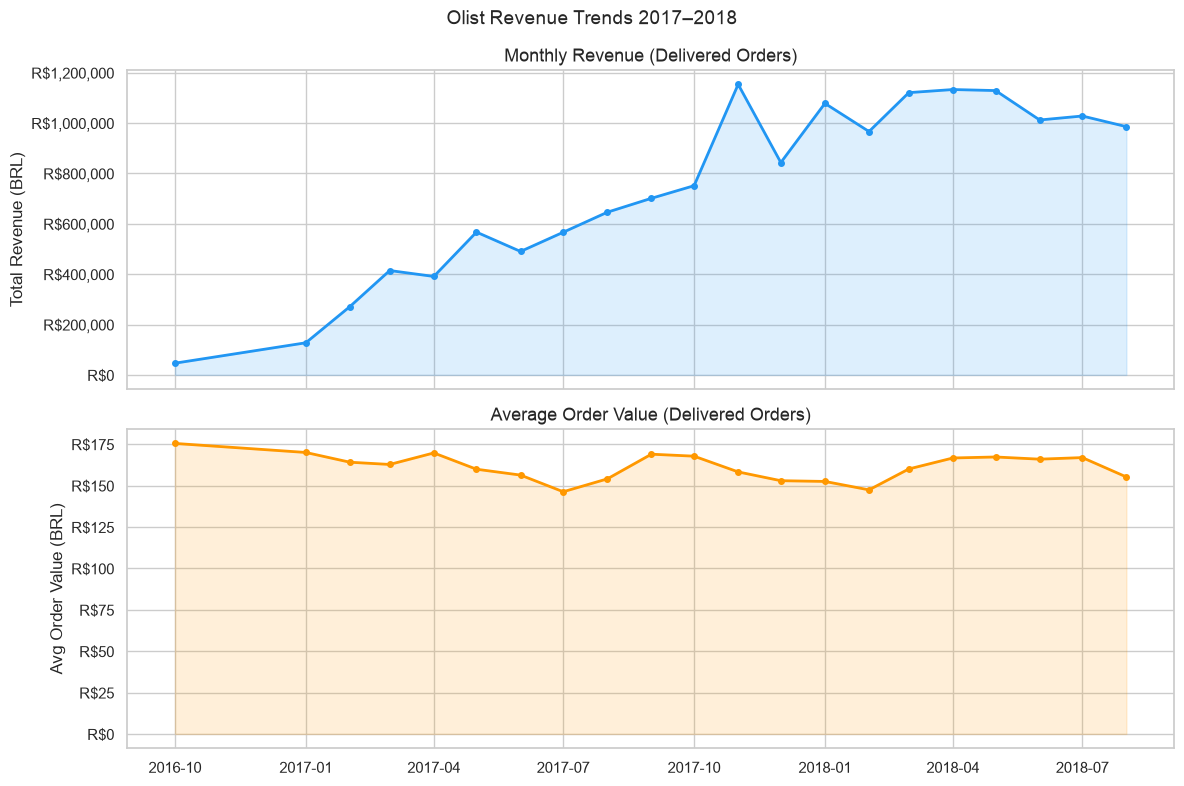

In [71]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Drop the outlier months with <10 orders (2016-09, 2016-12)
monthly_plot = monthly_revenue[monthly_revenue['n_orders'] >= 10].copy()

# Total revenue
axes[0].plot(monthly_plot['month'], monthly_plot['total_revenue'], 
             color='#2196F3', linewidth=2, marker='o', markersize=4)
axes[0].fill_between(monthly_plot['month'], monthly_plot['total_revenue'], 
                     alpha=0.15, color='#2196F3')
axes[0].set_title('Monthly Revenue (Delivered Orders)', fontsize=13)
axes[0].set_ylabel('Total Revenue (BRL)')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'R${x:,.0f}'))

# Average order value
axes[1].plot(monthly_plot['month'], monthly_plot['avg_order_value'],
             color='#FF9800', linewidth=2, marker='o', markersize=4)
axes[1].fill_between(monthly_plot['month'], monthly_plot['avg_order_value'],
                     alpha=0.15, color='#FF9800')
axes[1].set_title('Average Order Value (Delivered Orders)', fontsize=13)
axes[1].set_ylabel('Avg Order Value (BRL)')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'R${x:,.0f}'))

plt.suptitle('Olist Revenue Trends 2017–2018', fontsize=14)
plt.tight_layout()
plt.show()

Revenue grows consistently through 2017–2018, while average order value stays flat around R$160–180. This implies that growth is coming from more orders, not higher spend per order.

Let's take a look at which product categories are associated with increased revenue. Freight-associated revenue may also vary by product category, as the cost associated with shipping products may depend on the size/weight of the product, which would be expectedly passed to consumers.

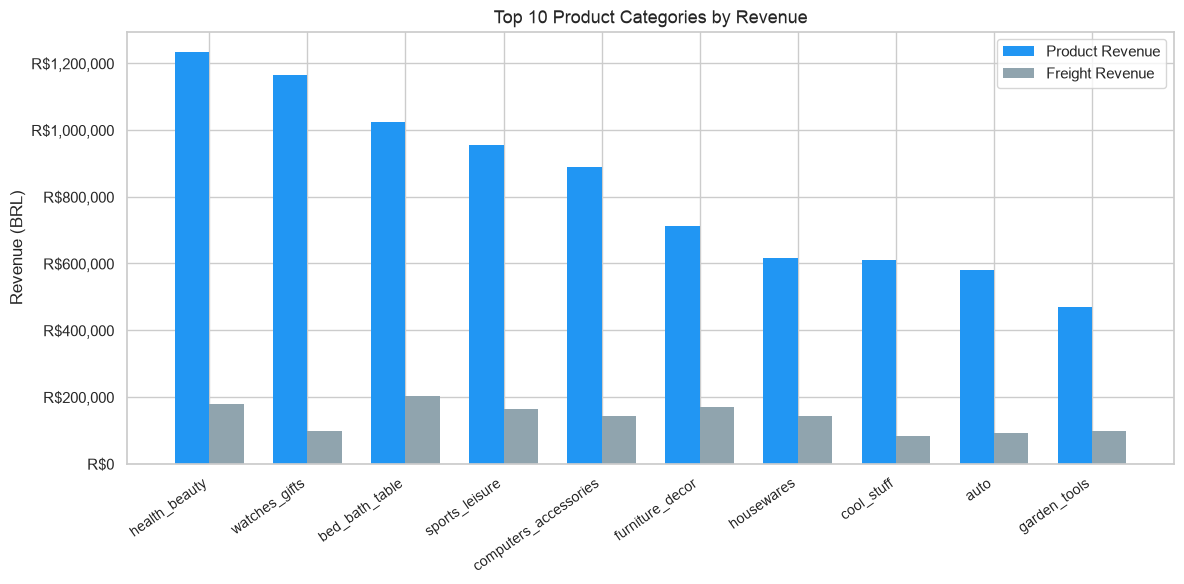

In [72]:
category_revenue = con.execute("""
    WITH cat_rev AS (
        SELECT
            t.product_category_name_english  AS category,
            SUM(oi.price)                    AS product_revenue,
            SUM(oi.freight_value)            AS freight_revenue,
            SUM(oi.price + oi.freight_value) AS total_revenue,
            COUNT(DISTINCT o.order_id)       AS n_orders
        FROM orders o
        JOIN order_items oi  ON o.order_id  = oi.order_id
        JOIN products p      ON oi.product_id = p.product_id
        JOIN product_category_name_translation t 
             ON p.product_category_name = t.product_category_name
        WHERE o.order_status = 'delivered'
        GROUP BY 1
        ORDER BY total_revenue DESC
    )
    SELECT * FROM cat_rev
    LIMIT 10
""").df()

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(category_revenue))
width = 0.35

bars1 = ax.bar(x - width/2, category_revenue['product_revenue'], width,
               label='Product Revenue', color='#2196F3', edgecolor='none')
bars2 = ax.bar(x + width/2, category_revenue['freight_revenue'], width,
               label='Freight Revenue', color='#90A4AE', edgecolor='none')

ax.set_xticks(x)
ax.set_xticklabels(category_revenue['category'], rotation=35, ha='right', fontsize=10)
ax.set_ylabel('Revenue (BRL)')
ax.set_title('Top 10 Product Categories by Revenue', fontsize=13)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'R${x:,.0f}'))
ax.legend()

plt.tight_layout()
plt.show()

# Compute freight as % of total
category_revenue['freight_pct'] = (category_revenue['freight_revenue'] / 
                                    category_revenue['total_revenue'] * 100).round(1)

Health & beauty leads in total revenue. Freight revenue varies quite a bit by category: furniture carries a ~19% freight burden versus ~8% for watches & gifts. These differences make sense given size and weight differences.

Now we can take a deeper look into the last two plots we created and ask: do high-revenue categories get there through volume or through ticket size? Plotting order count against average order value (with point size scaled to total revenue) shows where each category sits on this spectrum.

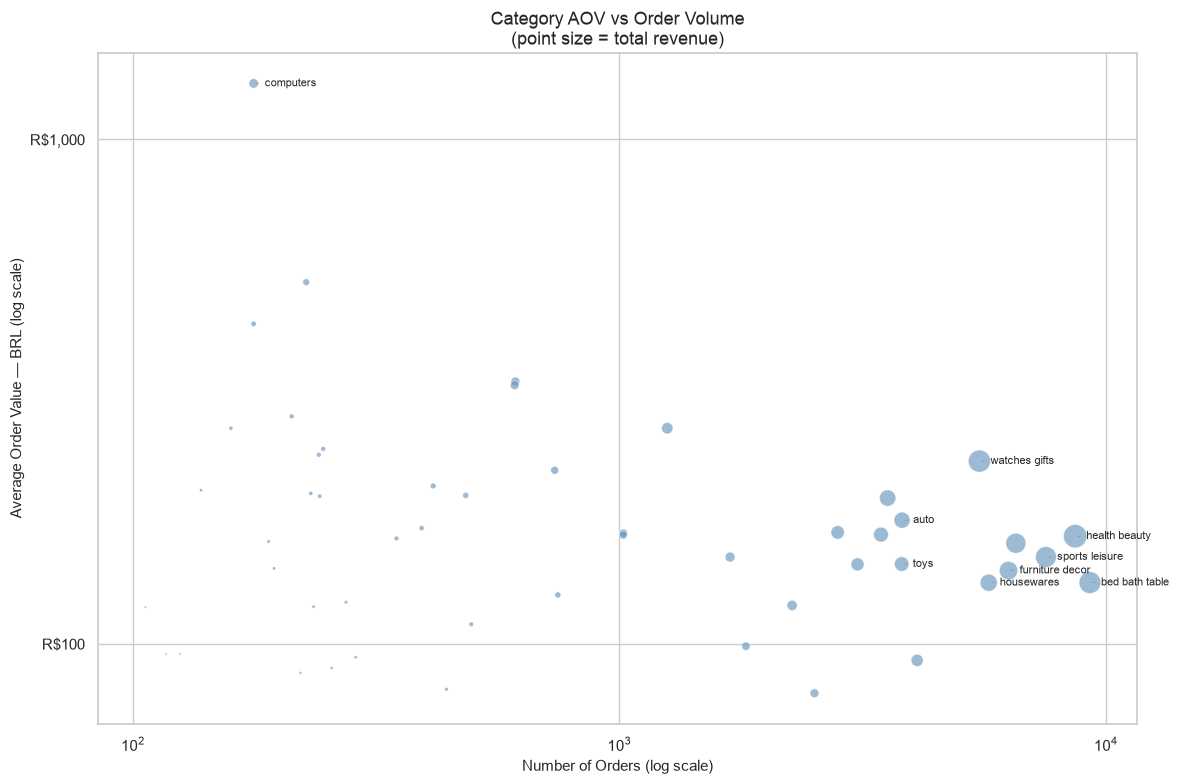

In [73]:
aov_category = con.execute("""
    WITH order_totals AS (
        SELECT
            o.order_id,
            t.product_category_name_english AS category,
            SUM(oi.price + oi.freight_value) AS order_value
        FROM orders o
        JOIN order_items oi ON o.order_id = oi.order_id
        JOIN products p ON oi.product_id = p.product_id
        JOIN product_category_name_translation t 
             ON p.product_category_name = t.product_category_name
        WHERE o.order_status = 'delivered'
        GROUP BY o.order_id, t.product_category_name_english
    )
    SELECT
        category,
        COUNT(order_id)      AS n_orders,
        AVG(order_value)     AS avg_order_value,
        SUM(order_value)     AS total_revenue
    FROM order_totals
    GROUP BY category
    HAVING COUNT(order_id) >= 100
    ORDER BY avg_order_value DESC
""").df()

label_these = {
    'health_beauty', 'computers', 'bed_bath_table',
    'furniture_decor', 'sports_leisure', 'housewares',
    'watches_gifts', 'toys', 'auto'
}

fig, ax = plt.subplots(figsize=(12, 8))

ax.scatter(aov_category['n_orders'], aov_category['avg_order_value'],
           s=aov_category['total_revenue'] / 5000,
           alpha=0.6, color='#5B8DB8', edgecolor='white', linewidth=0.5)

for _, row in aov_category.iterrows():
    if row['category'] in label_these:
        ax.annotate(row['category'].replace('_', ' '),
                    xy=(row['n_orders'], row['avg_order_value']),
                    xytext=(8, 0), textcoords='offset points',
                    fontsize=8, va='center',
                    arrowprops=dict(arrowstyle='-', color='gray', lw=0.4))

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Number of Orders (log scale)', fontsize=11)
ax.set_ylabel('Average Order Value — BRL (log scale)', fontsize=11)
ax.set_title('Category AOV vs Order Volume\n(point size = total revenue)', fontsize=13)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'R${x:,.0f}'))

plt.tight_layout()
plt.show()

There are no points in the upper-right quadrant, as categories with high volume tend to have lower AOVs. Computers have the highest AOV (~R$1,290) but low volume. We can see that the categories that drive most revenue are obtaining this revenue more though a large number of orders than average order value, including health_beauty and watches_gifts.

Next we wonder, to what degree are the large numbers of orders coming from the same set of customers repeatedly ordering?

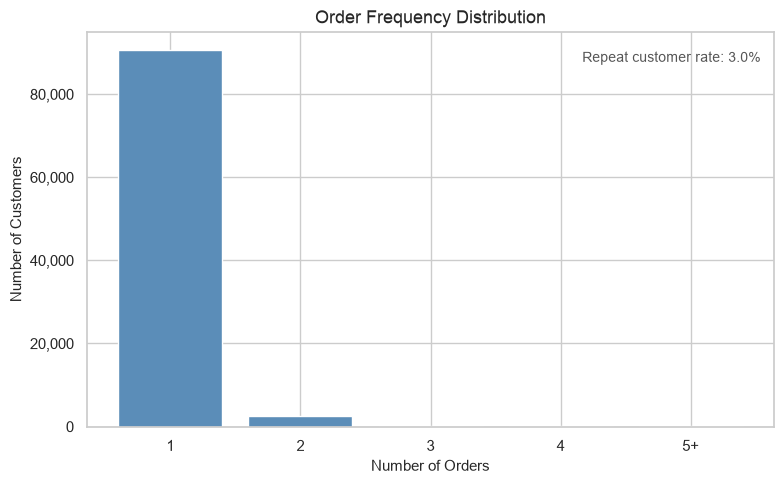

In [74]:
repeat_customers = con.execute("""
    WITH customer_orders AS (
        SELECT
            customer_unique_id,
            COUNT(DISTINCT o.order_id) AS n_orders
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
        GROUP BY customer_unique_id
    )
    SELECT
        n_orders,
        COUNT(*) AS n_customers,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_customers
    FROM customer_orders
    GROUP BY n_orders
    ORDER BY n_orders
""").df()

repeat_customers['order_group'] = repeat_customers['n_orders'].apply(
    lambda x: '5+' if x >= 5 else str(x)
)
plot_data = repeat_customers.groupby('order_group')['n_customers'].sum().reset_index()
plot_data['order_group'] = pd.Categorical(plot_data['order_group'], 
                                           categories=['1','2','3','4','5+'], 
                                           ordered=True)
plot_data = plot_data.sort_values('order_group')

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(plot_data['order_group'], plot_data['n_customers'], color='#5B8DB8', edgecolor='white')

ax.set_xlabel('Number of Orders', fontsize=11)
ax.set_ylabel('Number of Customers', fontsize=11)
ax.set_title('Order Frequency Distribution', fontsize=13)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))

repeat_rate = repeat_customers[repeat_customers['n_orders'] > 1]['n_customers'].sum() / repeat_customers['n_customers'].sum() * 100
ax.annotate(f'Repeat customer rate: {repeat_rate:.1f}%',
            xy=(0.98, 0.95), xycoords='axes fraction',
            ha='right', va='top', fontsize=10, color='#555555')

plt.tight_layout()
plt.show()

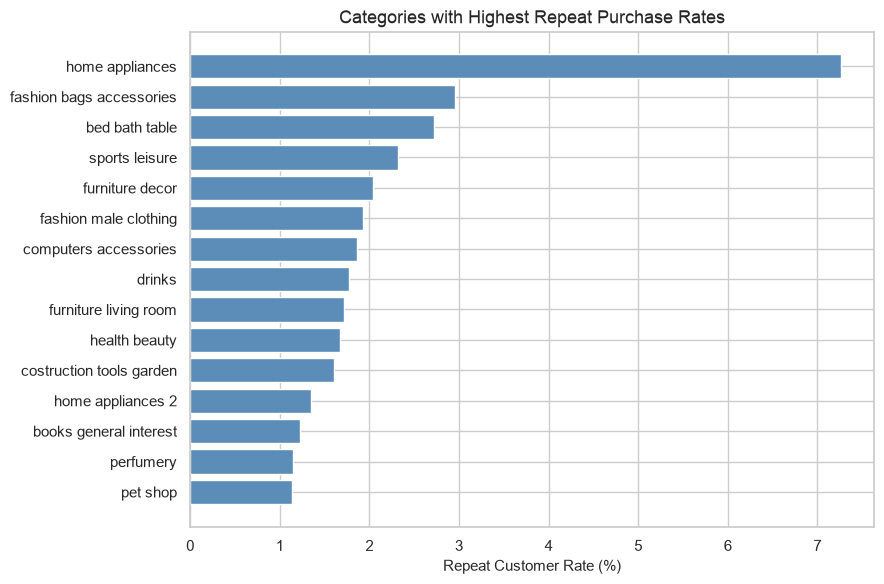

In [75]:
repeat_categories = con.execute("""
    WITH customer_category_orders AS (
        SELECT
            c.customer_unique_id,
            t.product_category_name_english AS category,
            COUNT(DISTINCT o.order_id) AS n_orders
        FROM orders o
        JOIN customers c    ON o.customer_id   = c.customer_id
        JOIN order_items oi ON o.order_id      = oi.order_id
        JOIN products p     ON oi.product_id   = p.product_id
        JOIN product_category_name_translation t
             ON p.product_category_name = t.product_category_name
        WHERE o.order_status = 'delivered'
        GROUP BY c.customer_unique_id, t.product_category_name_english
    )
    SELECT
        category,
        COUNT(*)                                                      AS total_customers,
        SUM(CASE WHEN n_orders > 1 THEN 1 ELSE 0 END)                AS repeat_customers,
        SUM(CASE WHEN n_orders > 1 THEN 1 ELSE 0 END) * 100.0 
            / COUNT(*)                                                AS repeat_rate
    FROM customer_category_orders
    GROUP BY category
    HAVING COUNT(*) >= 100
    ORDER BY repeat_rate DESC
    LIMIT 15
""").df()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(repeat_categories['category'].str.replace('_', ' '),
        repeat_categories['repeat_rate'],
        color='#5B8DB8')

ax.set_xlabel('Repeat Customer Rate (%)', fontsize=11)
ax.set_title('Categories with Highest Repeat Purchase Rates', fontsize=13)
ax.invert_yaxis()

plt.tight_layout()
plt.show()

Only 3% of customers place more than one order. This surprisingly low repeat rate may partly be an artifact of how the platform tracks customers across sessions. Among repeat buyers, home appliances tops the category list, with more than double the repeat rate of the next highest category. 

Next, we will examine out highest revenue associated categories over time. Do any product categories account for a disproportionate rate of revenue growth? Or is revenue growth generally well distributed across product categories?

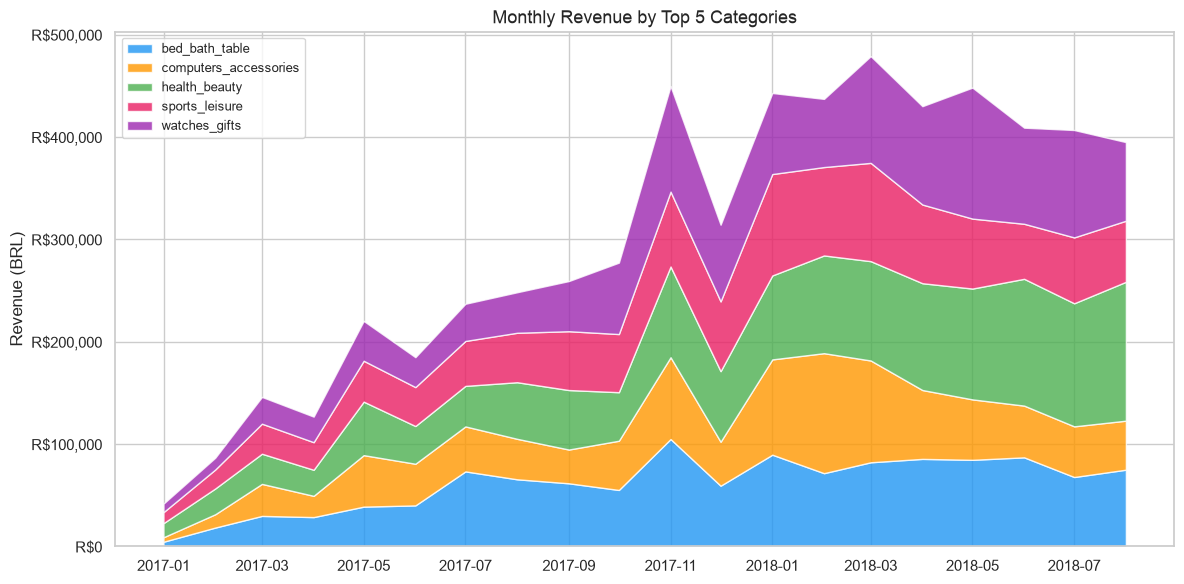

In [76]:
top5_cats = category_revenue.nlargest(5, 'total_revenue')['category'].tolist()

category_monthly = con.execute(f"""
    SELECT
        DATE_TRUNC('month', o.order_purchase_timestamp) AS month,
        t.product_category_name_english                 AS category,
        SUM(oi.price + oi.freight_value)                AS revenue
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN products p ON oi.product_id = p.product_id
    JOIN product_category_name_translation t 
         ON p.product_category_name = t.product_category_name
    WHERE o.order_status = 'delivered'
      AND t.product_category_name_english IN ({str(top5_cats)[1:-1]})
    GROUP BY 1, 2
    ORDER BY 1
""").df()

# Pivot for stacked area
pivot = category_monthly.pivot(index='month', columns='category', values='revenue').fillna(0)
pivot = pivot[pivot.index >= '2017-01-01']

fig, ax = plt.subplots(figsize=(12, 6))

colors = ['#2196F3', '#FF9800', '#4CAF50', '#E91E63', '#9C27B0']
ax.stackplot(pivot.index, pivot.T.values, labels=pivot.columns, colors=colors, alpha=0.8)

ax.set_title('Monthly Revenue by Top 5 Categories', fontsize=13)
ax.set_ylabel('Revenue (BRL)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'R${x:,.0f}'))
ax.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()

Growth appears to be broad across all five categories. There is a clear spike at November 2017 (which aligns with Black Friday?). Health & beauty is the most consistent contributor with relatively little seasonality.

Lets take a deeper look across more categories. We will make a heatmap showing the revenue attributed to each category and time point, where revenue is normalized to the per-category maximum. We will be able to see whether this November 2017 peak is consistent across product categories, and any other potential windows of time associated with revenue growth.  

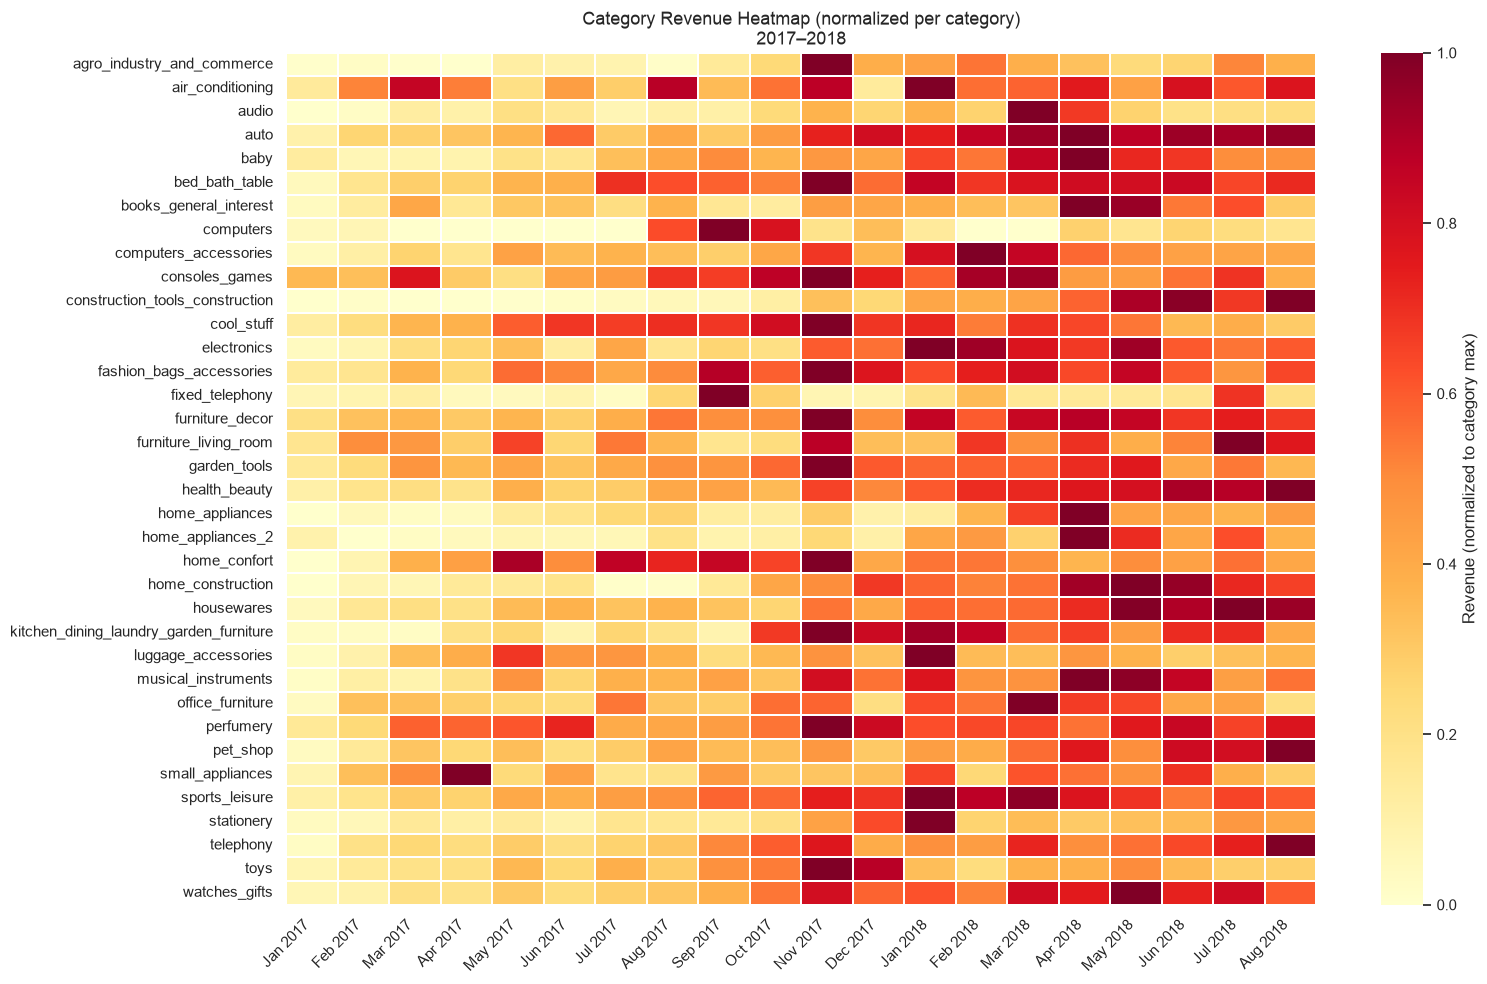

In [77]:
# Pivot all categories (not just top 5) with enough orders
cat_month_all = con.execute("""
    SELECT
        DATE_TRUNC('month', o.order_purchase_timestamp) AS month,
        t.product_category_name_english                 AS category,
        SUM(oi.price + oi.freight_value)                AS revenue
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN products p ON oi.product_id = p.product_id
    JOIN product_category_name_translation t 
         ON p.product_category_name = t.product_category_name
    WHERE o.order_status = 'delivered'
    GROUP BY 1, 2
    ORDER BY 1
""").df()

# Filter to 2017+ and categories with decent volume
cat_month_all = cat_month_all[cat_month_all['month'] >= '2017-01-01']

# Pivot
heatmap_pivot = cat_month_all.pivot(index='category', columns='month', values='revenue').fillna(0)

# Keep only categories with total revenue > 50k
heatmap_pivot = heatmap_pivot[heatmap_pivot.sum(axis=1) > 50000]

# Normalize each row by its own max so colors reflect growth pattern not absolute size
heatmap_norm = heatmap_pivot.div(heatmap_pivot.max(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(16, 10))

sns.heatmap(heatmap_norm, cmap='YlOrRd', ax=ax,
            linewidths=0.3, linecolor='white',
            cbar_kws={'label': 'Revenue (normalized to category max)'})

ax.set_title('Category Revenue Heatmap (normalized per category)\n2017–2018', fontsize=13)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticklabels([pd.Timestamp(t.get_text()).strftime('%b %Y') 
                    for t in ax.get_xticklabels()], rotation=45, ha='right')

plt.tight_layout()
plt.show()

The November 2017 spike shows up across almost every category. Most categories also appear to have sustained revenue growth from late 2017 and beyond, supporting the conclusion that revenue growth is consistent across product categories. Interestingly, computers, toys, and, to a lesser degree "home confort" (which I assume is mistranslated "home comfort") show a different pattern, with peaks taking place well before other product categories and not recovering. 

## Section 2: Seller Performance

Looking at which sellers generate the most revenue and whether delivery speed is related to review scores. Restricted to sellers with at least 50 delivered orders (418 sellers).

In [78]:
seller_performance = con.execute("""
    SELECT
        oi.seller_id,
        COUNT(DISTINCT o.order_id)                                                     AS n_orders,
        SUM(oi.price + oi.freight_value)                                               AS total_revenue,
        AVG(r.review_score)                                                            AS avg_review_score,
        AVG(DATE_DIFF('day', o.order_purchase_timestamp, 
                      o.order_delivered_customer_date))                                AS avg_delivery_days
    FROM orders o
    JOIN order_items oi     ON o.order_id    = oi.order_id
    JOIN order_reviews r    ON o.order_id    = r.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
    GROUP BY oi.seller_id
    HAVING COUNT(DISTINCT o.order_id) >= 50
    ORDER BY total_revenue DESC
""").df()

print(f"{len(seller_performance)} sellers with 50+ delivered orders")
seller_performance.head()

418 sellers with 50+ delivered orders


,seller_id,n_orders,total_revenue,avg_review_score,avg_delivery_days
0,4869f7a5dfa277a7dca6462dcf3b52b2,1116,245468.97,4.139474,14.866667
1,7c67e1448b00f6e969d365cea6b010ab,967,237880.59,3.354197,22.341679
2,4a3ca9315b744ce9f8e9374361493884,1753,231619.99,3.828630,14.365829
3,53243585a1d6dc2643021fd1853d8905,346,228644.09,4.128141,13.216080
4,fa1c13f2614d7b5c4749cbc52fecda94,574,199493.51,4.373913,13.219130


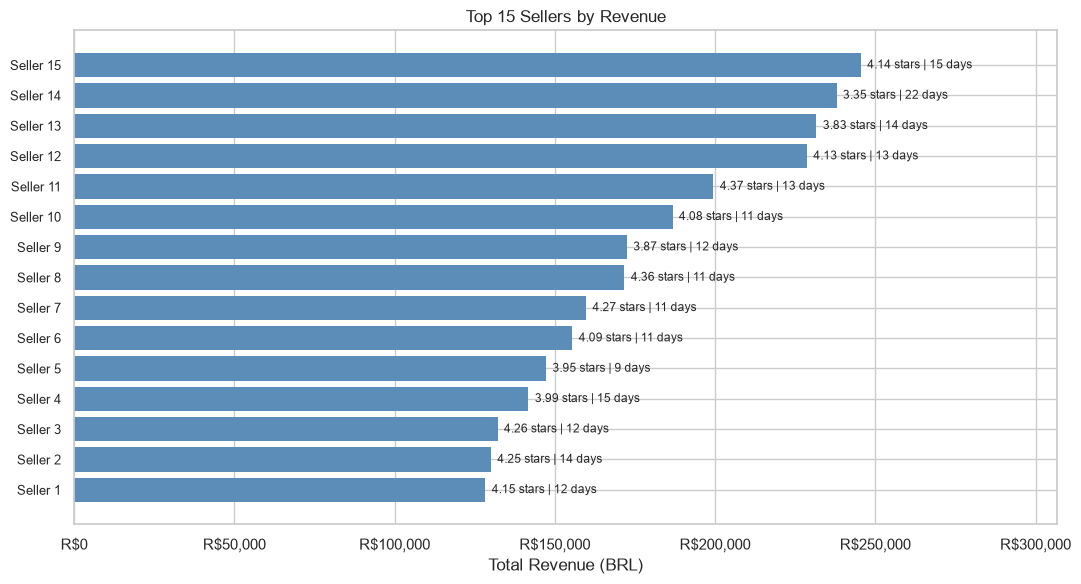

In [79]:
fig, ax = plt.subplots(figsize=(11, 6))

top15 = seller_performance.nlargest(15, 'total_revenue').sort_values('total_revenue')

bars = ax.barh(range(len(top15)), top15['total_revenue'], 
               color='#5B8DB8', edgecolor='none')

for bar, (_, row) in zip(bars, top15.iterrows()):
    ax.text(bar.get_width() + 2000, bar.get_y() + bar.get_height()/2,
            f'{row["avg_review_score"]:.2f} stars | {row["avg_delivery_days"]:.0f} days',
            va='center', fontsize=8.5)

ax.set_yticks(range(len(top15)))
ax.set_yticklabels([f'Seller {i+1}' for i in range(len(top15))], fontsize=9)
ax.set_xlabel('Total Revenue (BRL)')
ax.set_title('Top 15 Sellers by Revenue')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'R${x:,.0f}'))
ax.set_xlim(0, top15['total_revenue'].max() * 1.25)

plt.tight_layout()
plt.show()

There does not appear to be a consistent relationship between the number of stars the top sellers have and their associated total revenue, which I find unexpected. I am not seeing a clear average delivery timeline pattern either, but this may depend on the product categories each seller focuses on. Is there a relationship between delivery times and customer reviews?

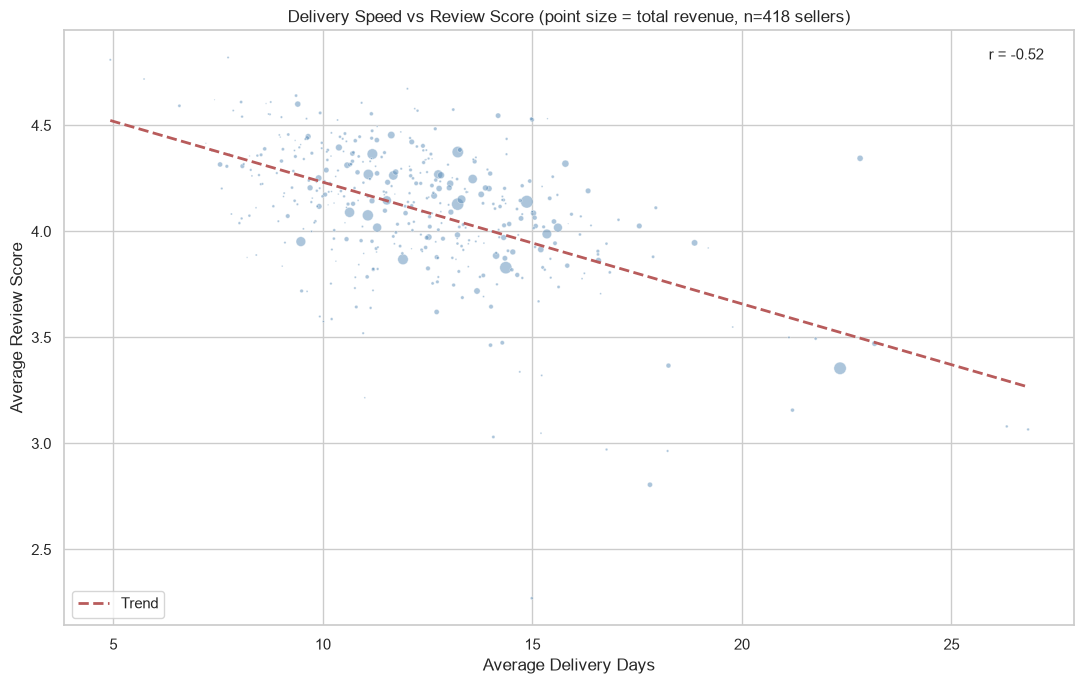

In [80]:
fig, ax = plt.subplots(figsize=(11, 7))

ax.scatter(seller_performance['avg_delivery_days'],
           seller_performance['avg_review_score'],
           s=seller_performance['total_revenue'] / 3000,
           alpha=0.5, color='#5B8DB8', edgecolor='white', linewidth=0.5)

z = np.polyfit(seller_performance['avg_delivery_days'], 
               seller_performance['avg_review_score'], 1)
p = np.poly1d(z)
x_line = np.linspace(seller_performance['avg_delivery_days'].min(),
                     seller_performance['avg_delivery_days'].max(), 100)
ax.plot(x_line, p(x_line), color='#B85B5B', linewidth=2, linestyle='--', label='Trend')

corr = seller_performance['avg_delivery_days'].corr(seller_performance['avg_review_score'])
ax.text(0.97, 0.97, f'r = {corr:.2f}', transform=ax.transAxes,
        ha='right', va='top', fontsize=11,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

ax.set_xlabel('Average Delivery Days')
ax.set_ylabel('Average Review Score')
ax.set_title('Delivery Speed vs Review Score (point size = total revenue, n=418 sellers)')
ax.legend()

plt.tight_layout()
plt.show()

There's a moderate negative correlation (r = -0.52) between delivery time and review score. Delivery explains about 27% of the variance in review scores, indicating that there is remaining variation to be modeled here. 

Let's explore the revenue-delivery time relationship (or lack thereof) in more detail. I generally would expect that high-revenue sellers on average have shorter delivery times. 

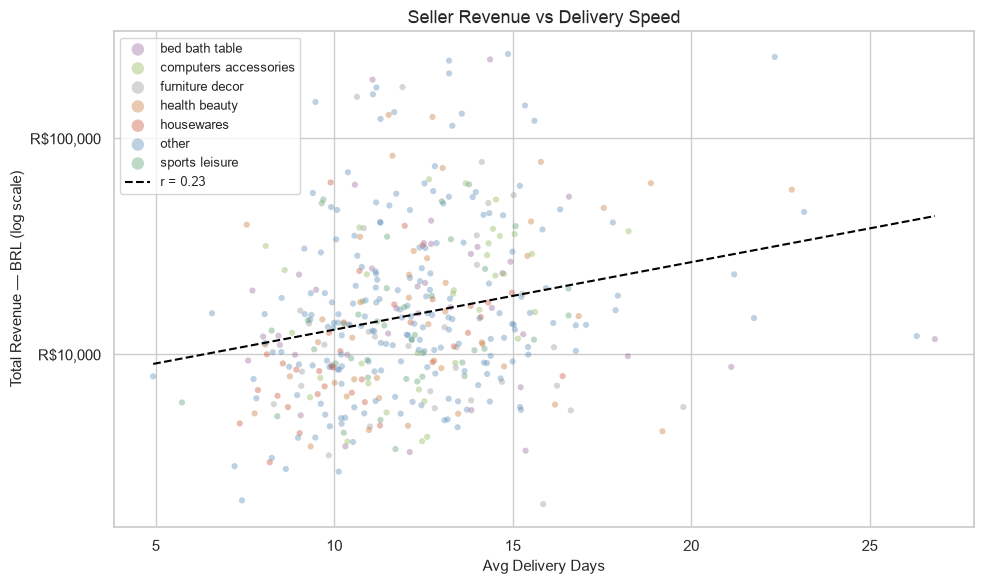

In [81]:
seller_category = con.execute("""
    SELECT
        ranked.seller_id,
        t.product_category_name_english AS majority_category
    FROM (
        SELECT
            oi.seller_id,
            p.product_category_name,
            COUNT(*) AS n_items,
            ROW_NUMBER() OVER (PARTITION BY oi.seller_id ORDER BY COUNT(*) DESC) AS rn
        FROM order_items oi
        JOIN products p ON oi.product_id = p.product_id
        GROUP BY oi.seller_id, p.product_category_name
    ) ranked
    JOIN product_category_name_translation t
         ON ranked.product_category_name = t.product_category_name
    WHERE rn = 1
""").df()

seller_performance = seller_performance.merge(seller_category, on='seller_id', how='left')

from scipy import stats

# collapse long tail of categories
top_cats = seller_performance['majority_category'].value_counts().head(6).index
seller_performance['cat_label'] = seller_performance['majority_category'].apply(
    lambda x: x.replace('_', ' ') if x in top_cats else 'other'
)

colors = ['#5B8DB8', '#C97B3A', '#5A9E6F', '#9B6B9B', '#C9563A', '#8DB85B', '#999999']
cat_order = list(seller_performance['cat_label'].value_counts().index)
color_map = {cat: colors[i] for i, cat in enumerate(cat_order)}

log_revenue = np.log10(seller_performance['total_revenue'])
slope, intercept, r, p, _ = stats.linregress(seller_performance['avg_delivery_days'], log_revenue)

fig, ax = plt.subplots(figsize=(10, 6))

for cat, group in seller_performance.groupby('cat_label'):
    ax.scatter(group['avg_delivery_days'], group['total_revenue'],
               alpha=0.4, s=20, color=color_map[cat], edgecolor='none', label=cat)

x_range = np.linspace(seller_performance['avg_delivery_days'].min(),
                      seller_performance['avg_delivery_days'].max(), 200)
ax.plot(x_range, 10 ** (slope * x_range + intercept),
        color='black', linewidth=1.5, linestyle='--', label=f'r = {r:.2f}')

ax.set_yscale('log')
ax.set_xlabel('Avg Delivery Days', fontsize=11)
ax.set_ylabel('Total Revenue — BRL (log scale)', fontsize=11)
ax.set_title('Seller Revenue vs Delivery Speed', fontsize=13)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'R${x:,.0f}'))
ax.legend(fontsize=9, markerscale=2)

plt.tight_layout()
plt.show()

Unexpectedly, there is actually a positive correlation between delivery days and total revenue. And it does not appear that product category is confounding delivery time. This plot generally agrees with the bar plot that we were looking at previously. 

Slow delivery and low review scores may pose concern for sellers, but a seller only poses a real problem for the platform if they're doing meaningful volume. Let's flag sellers in the bottom third of review scores and top half of delivery times, then look at where they fall on revenue. 

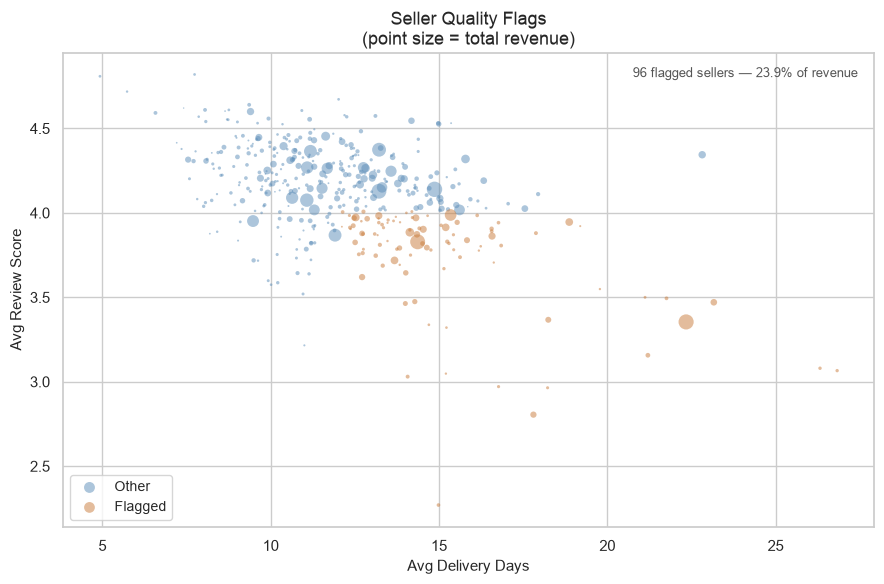

In [82]:
delivery_thresh = seller_performance['avg_delivery_days'].median()
review_thresh   = seller_performance['avg_review_score'].quantile(0.33)

seller_performance['flagged'] = (
    (seller_performance['avg_delivery_days'] > delivery_thresh) &
    (seller_performance['avg_review_score']  < review_thresh)
)

fig, ax = plt.subplots(figsize=(9, 6))

for flagged, group in seller_performance.groupby('flagged'):
    ax.scatter(group['avg_delivery_days'], group['avg_review_score'],
               s=group['total_revenue'] / 2000,
               alpha=0.5,
               color='#C97B3A' if flagged else '#5B8DB8',
               edgecolor='none',
               label='Flagged' if flagged else 'Other')

ax.set_xlabel('Avg Delivery Days', fontsize=11)
ax.set_ylabel('Avg Review Score', fontsize=11)
ax.set_title('Seller Quality Flags\n(point size = total revenue)', fontsize=13)
ax.legend(fontsize=10)

n_flagged = seller_performance['flagged'].sum()
flagged_rev = seller_performance.loc[seller_performance['flagged'], 'total_revenue'].sum()
total_rev   = seller_performance['total_revenue'].sum()

ax.annotate(f"{n_flagged} flagged sellers — {flagged_rev/total_rev*100:.1f}% of revenue",
            xy=(0.98, 0.97), xycoords='axes fraction',
            ha='right', va='top', fontsize=9, color='#555555')

plt.tight_layout()
plt.show()

96 sellers are both in the bottom third in review scores and top half in delivery time. These sellers account for roughly 24% of revenue in this subset, some of whom are selling a meaningfully large volume. With data collected beyond the timeframe of this set, it would be interesting to examine whether the revenue associated with these sellers trends cohesively with the remaining sellers in the dataset, or eventually starts to lag behind. 

## Overall Conclusions

Revenue on the Olist platform grew steadily through 2017–2018, driven by order volume rather than increasing spend per order (AOV stayed flat around R$160–180). Only 3% of customers placed more than one order, so almost all of this growth appears to be coming from new customers. Repeat rates vary meaningfully by category, however, suggesting retention may not be uniformly low across the platform.

Category economics vary quite a bit: health & beauty dominates through volume, while computers and home appliances have the highest AOVs but low order counts. No category does both. The November 2017 Black Friday spike is visible across nearly every category.

On the seller side, delivery speed has a moderate relationship with review scores (r = -0.52), but delivery alone only explains about a quarter of the variance. Interestingly, higher-revenue sellers tend to have slightly longer average delivery windows. This is potentially a volume effect rather than anything causal, and not explained by sellers specializing in large or heavy items. A subset of 96 sellers fall below the bottom third in review scores and above the median in delivery time; together they account for roughly 24% of revenue in this cohort, suggesting underperformance isn't confined to small or marginal sellers.

**Limitations:** Seller identities are anonymized, so we are limited on the level information we can include about each seller. The 3% repeat rate may also be understated if customers return to sellers through direct channels outside the platform or there are issues in identifying customer profiles. 